# ACTIVITY 1: DATASET PREPARATION ACTIVITY

**Unit:** Unit I – Foundations & Data Preparation  
**Course:** Machine Learning [ADPC509] 

**Roll no:** AD3103 

## Objective
To inspect a dataset, identify data-quality issues, perform basic exploratory data analysis (EDA), and prepare data for a machine-learning workflow.



## Step 1: Select a dataset
**Dataset:** https://www.kaggle.com/datasets/mirichoi0218/insurance

**File:** `insurance.csv`

## Step 2: Load and inspect the dataset



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv('insurance.csv')

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

Dataset loaded successfully!
Number of rows and columns: (1338, 7)


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("Column names:")
print(df.columns.tolist())

print("Data types:")
print(df.dtypes)

Number of rows: 1338
Number of columns: 7
Column names:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
Data types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


EXPLANATION:

| Column | Meaning |
|---|---|
| `age` | Age of the individual in years |
| `sex` | Sex of the individual |
| `bmi` | Body Mass Index |
| `children` | Number of children/dependants covered by insurance |
| `smoker` | Smoking status (yes/no) |
| `region` | Residential region |
| `charges` | Medical insurance charges |

The dataset describes individuals and the medical insurance charges associated with them.

## Step 3: Identify data types and basic statistics


In [4]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = df.select_dtypes(include=['object']).columns

print("Numerical columns:")
print(list(numerical_columns))

print("Categorical columns:")
print(list(categorical_columns))

Numerical columns:
['age', 'bmi', 'children', 'charges']
Categorical columns:
['sex', 'smoker', 'region']


In [5]:
display(df.describe())

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [6]:
print("Unique values in categorical columns:")
for column in categorical_columns:
    print("\n", column)
    print(df[column].unique())

print("\nMinimum and maximum of numerical columns:")
display(df[numerical_columns].agg(['min', 'max']))

Unique values in categorical columns:

 sex
['female' 'male']

 smoker
['yes' 'no']

 region
['southwest' 'southeast' 'northwest' 'northeast']

Minimum and maximum of numerical columns:


,age,bmi,children,charges
min,18,15.96,0,1121.87390
max,64,53.13,5,63770.42801


## Step 4: Identify missing values



In [7]:
missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Value Count': missing_count,
    'Missing Value Percentage': missing_percentage
})

display(missing_table)

print("Columns with no missing values:")
print(missing_table[missing_table['Missing Value Count'] == 0].index.tolist())

print("Columns with missing values:")
print(missing_table[missing_table['Missing Value Count'] > 0].index.tolist())

,Missing Value Count,Missing Value Percentage
age,0,0.0
sex,0,0.0
bmi,0,0.0
children,0,0.0
smoker,0,0.0
region,0,0.0
charges,0,0.0


Columns with no missing values:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
Columns with missing values:
[]


### Missing-value findings

The table above shows the actual missing-value count and percentage for every column. If a column has 0 missing values, it does not need missing-value treatment.

## Step 5: Handle missing values



In [8]:
clean_df = df.copy()

In [9]:
for column in numerical_columns:
    clean_df[column] = clean_df[column].fillna(clean_df[column].median())

for column in categorical_columns:
    if clean_df[column].isnull().sum() > 0:
        clean_df[column] = clean_df[column].fillna(clean_df[column].mode()[0])

print("Missing values after handling:")
print(clean_df.isnull().sum())

Missing values after handling:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


### Explanation the result

The output above verifies the missing-value counts again. If the dataset has no missing values, the copy remains unchanged in this step. Median is suitable for numerical data and mode is suitable for categorical data.

## Step 6: Check duplicate records and consistency



In [10]:
print("Number of duplicate rows before removal:", clean_df.duplicated().sum())

Number of duplicate rows before removal: 1


In [11]:
clean_df = clean_df.drop_duplicates()

print("Number of duplicate rows after removal:", clean_df.duplicated().sum())
print("Shape after removing duplicates:", clean_df.shape)

Number of duplicate rows after removal: 0
Shape after removing duplicates: (1337, 7)


In [12]:
for column in categorical_columns:
    print("\nDistinct values in", column, ":")
    print(clean_df[column].unique())


Distinct values in sex :
['female' 'male']

Distinct values in smoker :
['yes' 'no']

Distinct values in region :
['southwest' 'southeast' 'northwest' 'northeast']


## Step 7: Perform basic Exploratory Data Analysis (EDA)



In [13]:
print("Summary statistics:")
display(clean_df.describe())

print("Frequency counts for sex:")
display(clean_df['sex'].value_counts())

print("Frequency counts for smoker:")
display(clean_df['smoker'].value_counts())

print("Frequency counts for region:")
display(clean_df['region'].value_counts())

Summary statistics:


,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


Frequency counts for sex:


,count
sex,
male,675
female,662


Frequency counts for smoker:


,count
smoker,
no,1063
yes,274


Frequency counts for region:


,count
region,
southeast,364
southwest,325
northwest,324
northeast,324


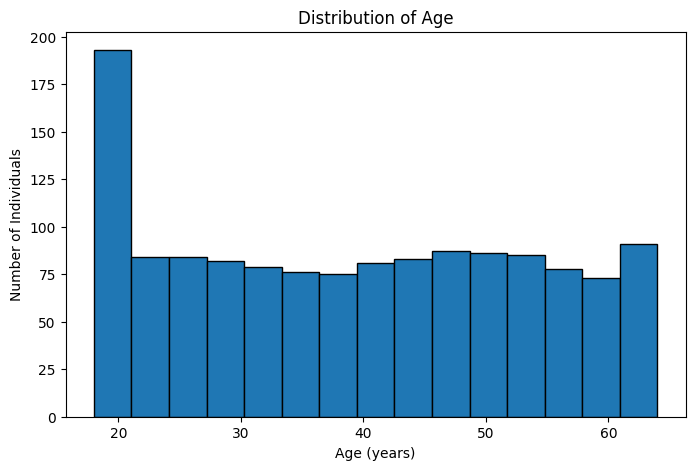

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(clean_df['age'], bins=15, edgecolor='black')
plt.title('Distribution of Age')
plt.xlabel('Age (years)')
plt.ylabel('Number of Individuals')
plt.show()

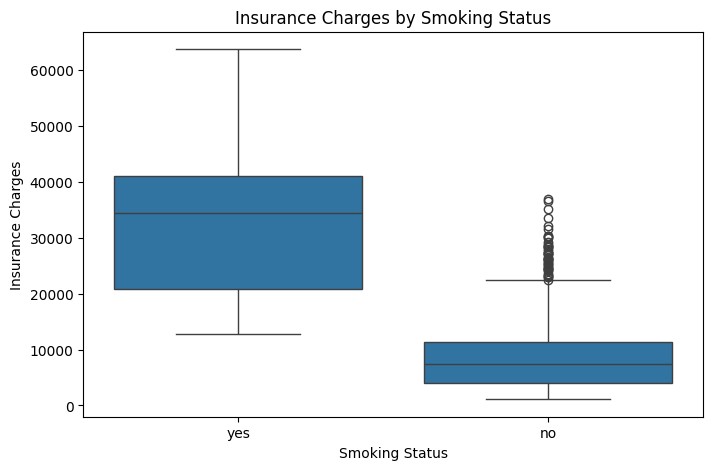

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_df, x='smoker', y='charges')
plt.title('Insurance Charges by Smoking Status')
plt.xlabel('Smoking Status')
plt.ylabel('Insurance Charges')
plt.show()

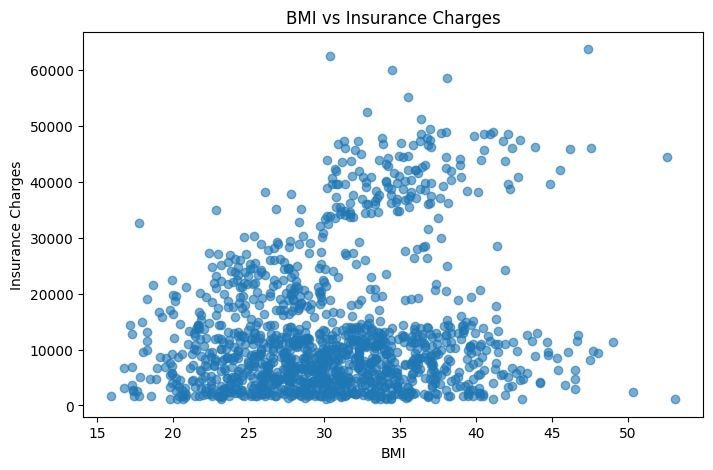

In [16]:
plt.figure(figsize=(8, 5))
plt.scatter(clean_df['bmi'], clean_df['charges'], alpha=0.6)
plt.title('BMI vs Insurance Charges')
plt.xlabel('BMI')
plt.ylabel('Insurance Charges')
plt.show()

### Observations

1. Age Distribution (Histogram): Most individuals in the dataset are between 18 and 60 years of age. The dataset contains individuals from 18 to 64 years old, with younger age groups appearing more frequently.

2. Insurance Charges by Smoking Status (Box Plot): Smokers have much higher insurance charges than non-smokers. The average insurance charge for smokers is approximately 32,050, while for non-smokers it is approximately 8,434.

3. BMI vs Insurance Charges (Scatter Plot): The scatter plot shows a weak positive relationship between BMI and insurance charges. This means that charges tend to increase slightly as BMI increases, but the points are widely spread.

## Step 8: Encode categorical features



In [17]:
encoded_df = pd.get_dummies(
    clean_df,
    columns=['sex', 'smoker', 'region'],
    drop_first=True,
    dtype=int
)

print("Data before encoding:")
display(clean_df.head())

print("Data after encoding:")
display(encoded_df.head())

print("New column names:")
print(encoded_df.columns.tolist())

Data before encoding:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Data after encoding:


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


New column names:
['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


### Explanation- The representation before and after encoding

Before encoding, columns such as `sex`, `smoker` and `region` contain text labels. After one-hot encoding, these categories are represented by numerical 0 and 1 columns.

For example, a column such as `smoker_yes` indicates whether the individual is a smoker: 1 means yes and 0 means the reference category (no). The same approach is used for the other nominal categories.

## Step 9: Scale numerical features where appropriate



In [18]:
scaler = StandardScaler()

columns_to_scale = ['age', 'bmi', 'children']

encoded_df[columns_to_scale] = scaler.fit_transform(
    encoded_df[columns_to_scale]
)

print("Data after scaling:")
display(encoded_df.head())

print("Mean of scaled features (approximately 0):")
print(encoded_df[columns_to_scale].mean())

print("Standard deviation of scaled features (approximately 1):")
print(encoded_df[columns_to_scale].std())

Data after scaling:


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,-1.440418,-0.453160,-0.909234,16884.92400,0,1,0,0,1
1,-1.511647,0.509422,-0.079442,1725.55230,1,0,0,1,0
2,-0.799350,0.383155,1.580143,4449.46200,1,0,0,1,0
3,-0.443201,-1.305052,-0.909234,21984.47061,1,0,1,0,0
4,-0.514431,-0.292456,-0.909234,3866.85520,1,0,1,0,0


Mean of scaled features (approximately 0):
age        -6.643070e-17
bmi        -2.285216e-16
children    3.852980e-17
dtype: float64
Standard deviation of scaled features (approximately 1):
age         1.000374
bmi         1.000374
children    1.000374
dtype: float64


### Scaling method

**Scaling method used:** Standardisation using `StandardScaler`.

**Features scaled:** `age`, `bmi`, `children`.

**Not scaled:** `charges` (possible target).


## Step 10: Save the prepared dataset



In [19]:
prepared_df = encoded_df.copy()

print("Final prepared dataset shape:", prepared_df.shape)

print("Missing values in prepared dataset:")
print(prepared_df.isnull().sum())

print("Total missing values:", prepared_df.isnull().sum().sum())

print("Duplicate rows in prepared dataset:", prepared_df.duplicated().sum())

Final prepared dataset shape: (1337, 9)
Missing values in prepared dataset:
age                 0
bmi                 0
children            0
charges             0
sex_male            0
smoker_yes          0
region_northwest    0
region_southeast    0
region_southwest    0
dtype: int64
Total missing values: 0
Duplicate rows in prepared dataset: 0


In [20]:
prepared_df.to_csv('Insurance_Prepared.csv', index=False)

print("Prepared dataset saved successfully as Insurance_Prepared.csv")

Prepared dataset saved successfully as Insurance_Prepared.csv


In [21]:
display(prepared_df.head())

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,-1.440418,-0.453160,-0.909234,16884.92400,0,1,0,0,1
1,-1.511647,0.509422,-0.079442,1725.55230,1,0,0,1,0
2,-0.799350,0.383155,1.580143,4449.46200,1,0,0,1,0
3,-0.443201,-1.305052,-0.909234,21984.47061,1,0,1,0,0
4,-0.514431,-0.292456,-0.909234,3866.85520,1,0,1,0,0


### 10.4 Download the prepared CSV file


In [22]:
from google.colab import files
files.download('Insurance_Prepared.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

In this activity, the Insurance dataset was selected and inspected. The dataset structure, column names, data types and numerical summary statistics were reviewed. Missing values were counted and their percentages were calculated; any missing numerical values were filled with the median and missing categorical values with the mode. Duplicate rows were checked and exact duplicate records were removed. Categorical values were inspected for consistency. Basic EDA was performed using frequency counts, a histogram, a box plot and a scatter plot. The nominal categorical columns were converted using one-hot encoding. The numerical input features `age`, `bmi` and `children` were standardised using StandardScaler, while the possible target column `charges` was kept unchanged. Finally, the dataset was prepared.
